In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv')

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
x = df.drop(columns=['Outcome'])
y = df.iloc[:,8:]

In [7]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=2)

In [8]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)
y_pred = lr.predict(x_test)

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:
from sklearn.metrics import classification_report,confusion_matrix,precision_score,accuracy_score
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84       109
           1       0.63      0.49      0.55        45

    accuracy                           0.77       154
   macro avg       0.72      0.68      0.70       154
weighted avg       0.75      0.77      0.76       154



In [10]:
confusion_matrix(y_test,y_pred)

array([[96, 13],
       [23, 22]])

In [11]:
precision_score(y_test,y_pred,average='weighted')

0.7546655025646621

In [12]:
accuracy_score(y_test,y_pred)

0.7662337662337663

In [13]:
y_score = lr.predict_proba(x_test)[:,1]

In [14]:
y_score

array([0.04956581, 0.17457568, 0.09368694, 0.25493237, 0.63550153,
       0.11678027, 0.0656944 , 0.42187759, 0.04867264, 0.57569574,
       0.33862786, 0.41300712, 0.69852596, 0.1997506 , 0.02001093,
       0.82467923, 0.86661518, 0.03101877, 0.25526168, 0.89486568,
       0.95243538, 0.83469031, 0.11747631, 0.44687153, 0.0892603 ,
       0.06887501, 0.65126531, 0.41204032, 0.17867019, 0.28703555,
       0.24533923, 0.43905019, 0.00942967, 0.24269903, 0.3515109 ,
       0.96162254, 0.34373392, 0.80931265, 0.2938435 , 0.05087815,
       0.18193482, 0.08675994, 0.42227794, 0.18744237, 0.03012359,
       0.03950681, 0.24752138, 0.42778884, 0.1053474 , 0.37969397,
       0.99354661, 0.10651205, 0.39082425, 0.76883368, 0.36862569,
       0.45781159, 0.95032009, 0.41979632, 0.39119384, 0.04378276,
       0.37296035, 0.90126339, 0.8817498 , 0.88840189, 0.33090772,
       0.06920875, 0.95266818, 0.20055527, 0.26054528, 0.35451846,
       0.10359404, 0.08170456, 0.45049357, 0.09219229, 0.08649

# now find TPR and FPR for different threshold leavels

In [15]:
from sklearn.metrics import roc_curve
fpr , tpr , thresholds = roc_curve(y_test,y_score)

In [16]:
thresholds

array([       inf, 0.99354661, 0.95266818, 0.95243538, 0.82467923,
       0.76883368, 0.76176359, 0.6836182 , 0.67524229, 0.67414036,
       0.65126531, 0.65076941, 0.63550153, 0.58631247, 0.57569574,
       0.56949273, 0.52492843, 0.47024189, 0.46127711, 0.45049357,
       0.43905019, 0.43883549, 0.42227794, 0.41979632, 0.41300712,
       0.41204032, 0.40495482, 0.37969397, 0.36862569, 0.31018733,
       0.30884335, 0.27789456, 0.2721182 , 0.25526168, 0.25493237,
       0.24752138, 0.24533923, 0.23665844, 0.22886119, 0.18193482,
       0.17867019, 0.17457568, 0.1732466 , 0.14644209, 0.1407544 ,
       0.11678027, 0.11493714, 0.11006588, 0.10651205, 0.0892603 ,
       0.08675994, 0.02001093, 0.01931667, 0.00160908])

In [17]:
import plotly.graph_objects as go
import numpy as np


# Generate a trace for ROC curve
trace0 = go.Scatter(
    x=fpr,
    y=tpr,
    mode='lines',
    name='ROC curve'
)

# Only label every nth point to avoid cluttering
n = 10
indices = np.arange(len(thresholds)) % n == 0  # Choose indices where index mod n is 0

trace1 = go.Scatter(
    x=fpr[indices],
    y=tpr[indices],
    mode='markers+text',
    name='Threshold points',
    text=[f"Thr={thr:.2f}" for thr in thresholds[indices]],
    textposition='top center'
)


# Diagonal line
trace2 = go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode='lines',
    name='Random (Area = 0.5)',
    line=dict(dash='dash')
)

data = [trace0, trace1, trace2]

# Define layout with square aspect ratio
layout = go.Layout(
    title='Receiver Operating Characteristic',
    xaxis=dict(title='False Positive Rate'),
    yaxis=dict(title='True Positive Rate'),
    autosize=False,
    width=800,
    height=800,
    showlegend=False
)

# Define figure and add data
fig = go.Figure(data=data, layout=layout)

# Show figure
fig.show()


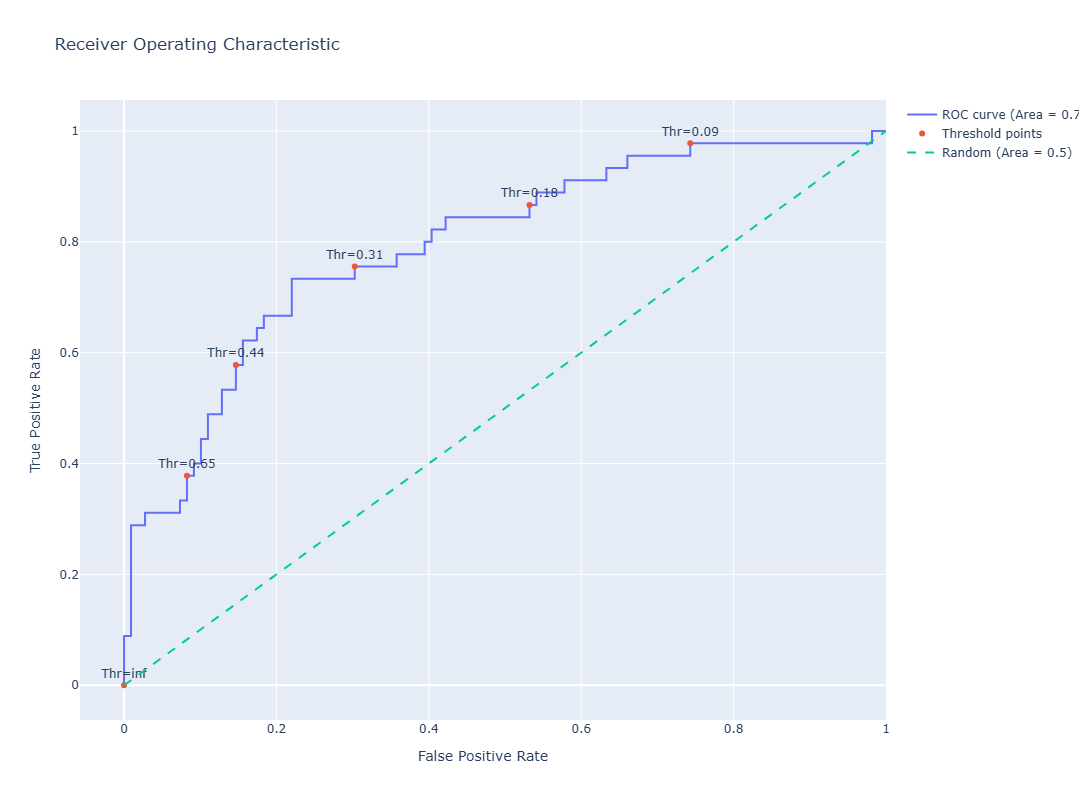

In [18]:
import plotly.graph_objects as go
import numpy as np
from sklearn.metrics import roc_auc_score

# Assuming fpr, tpr, thresholds are already calculated as before
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# Calculate the AUC (Area Under the Curve)
roc_auc = roc_auc_score(y_test, y_score)

# Generate a trace for ROC curve
trace0 = go.Scatter(
    x=fpr,
    y=tpr,
    mode='lines',
    name=f'ROC curve (Area = {roc_auc:.2f})'
)

# Only label every nth point to avoid cluttering
n = 10
indices = np.arange(len(thresholds)) % n == 0  # Choose indices where index mod n is 0

trace1 = go.Scatter(
    x=fpr[indices],
    y=tpr[indices],
    mode='markers+text',
    name='Threshold points',
    text=[f"Thr={thr:.2f}" for thr in thresholds[indices]],
    textposition='top center'
)

# Diagonal line
trace2 = go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode='lines',
    name='Random (Area = 0.5)',
    line=dict(dash='dash')
)

data = [trace0, trace1, trace2]

# Define layout with square aspect ratio
layout = go.Layout(
    title='Receiver Operating Characteristic',
    xaxis=dict(title='False Positive Rate'),
    yaxis=dict(title='True Positive Rate'),
    autosize=False,
    width=800,
    height=800,
    showlegend=True
)

# Define figure and add data
fig = go.Figure(data=data, layout=layout)

# Show figure
fig.show()


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning:

The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`



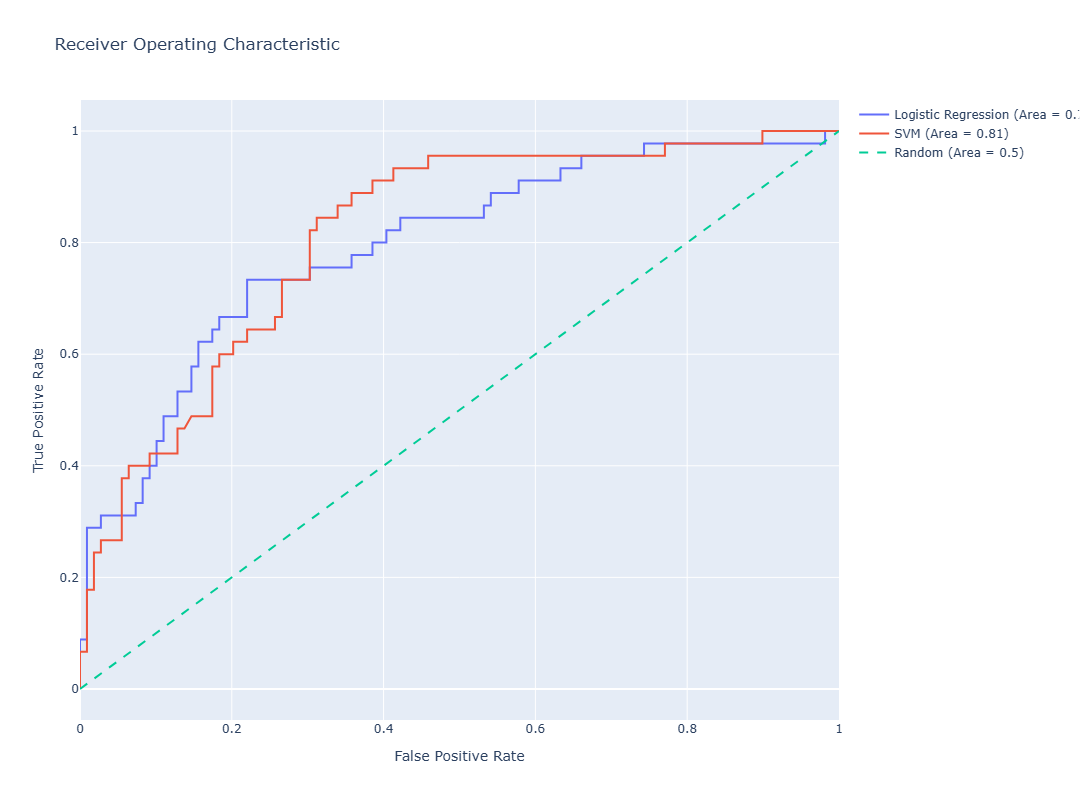

In [19]:
import numpy as np
import plotly.graph_objects as go
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler

# Assuming that X_train, X_test, y_train, y_test are already defined

# SVM requires feature scaling for better performance
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(x_train, y_train)
lr_scores = lr_model.predict_proba(x_test)[:,1]

# SVM model
svm_model = SVC(probability=True)
svm_model.fit(x_train_scaled, y_train)
svm_scores = svm_model.predict_proba(x_test_scaled)[:,1]

# Generate ROC curve data for logistic regression model
lr_fpr, lr_tpr, lr_thresholds = roc_curve(y_test, lr_scores)
lr_auc = roc_auc_score(y_test, lr_scores)

# Generate ROC curve data for SVM model
svm_fpr, svm_tpr, svm_thresholds = roc_curve(y_test, svm_scores)
svm_auc = roc_auc_score(y_test, svm_scores)

# Generate a trace for the Logistic Regression ROC curve
trace0 = go.Scatter(
    x=lr_fpr,
    y=lr_tpr,
    mode='lines',
    name=f'Logistic Regression (Area = {lr_auc:.2f})'
)

# Generate a trace for the SVM ROC curve
trace1 = go.Scatter(
    x=svm_fpr,
    y=svm_tpr,
    mode='lines',
    name=f'SVM (Area = {svm_auc:.2f})'
)

# Diagonal line
trace2 = go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode='lines',
    name='Random (Area = 0.5)',
    line=dict(dash='dash')
)

data = [trace0, trace1, trace2]

# Define layout with square aspect ratio
layout = go.Layout(
    title='Receiver Operating Characteristic',
    xaxis=dict(title='False Positive Rate'),
    yaxis=dict(title='True Positive Rate'),
    autosize=False,
    width=800,
    height=800,
    showlegend=True
)

# Define figure and add data
fig = go.Figure(data=data, layout=layout)

# Show figure
fig.show()


In [20]:
import numpy as np
from sklearn.metrics import roc_curve

# 1. Get FPR, TPR, and thresholds from your model scores
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# 2. Calculate Youden's J Statistic for each threshold
j_scores = tpr - fpr

# 3. Find the index of the maximum J value
optimal_idx = np.argmax(j_scores)
optimal_threshold_youden = thresholds[optimal_idx]

print(f"Optimal Threshold (Youden's J): {optimal_threshold_youden}")

Optimal Threshold (Youden's J): 0.36862569458531563
